## Task 2: Feature Extraction and Matching

1. **Aim**

The aim of this experiment is to extract visual features from images and investigate how effectively these features can be matched between two images. The experiment uses Histogram of Oriented Gradients (HOG) and Scale-Invariant Feature Transform (SIFT), followed by feature matching under different image transformations.

2. **Objectives**

-Extract HOG feature descriptors from two images.

-Detect SIFT keypoints and calculate their descriptors.

-Match corresponding features using a brute-force matcher.

-Apply Lowe's ratio test to filter ambiguous matches.

-Investigate the effect of rotation and resizing on feature matching.

-Visualize and compare the matching results.

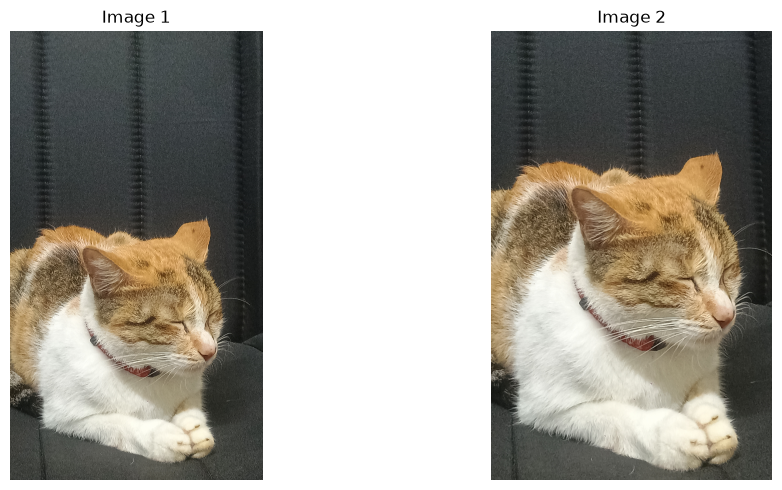

Image 1 dimensions: (8192, 4608, 3)
Image 2 dimensions: (6492, 4057, 3)


In [1]:

from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\Computer Vision Project")
INPUT_DIR = PROJECT_DIR / "input"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image1 = cv2.imread(str(INPUT_DIR / "original.jpg"))
image2 = cv2.imread(str(INPUT_DIR / "second.jpg"))

if image1 is None:
    raise FileNotFoundError("Check input/original.jpg")

if image2 is None:
    raise FileNotFoundError("Check input/second.jpg")

gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image 1")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Image 2")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Image 1 dimensions:", image1.shape)
print("Image 2 dimensions:", image2.shape)


## 2. HOG Feature Extraction

Histogram of Oriented Gradients describes local image shape using gradient orientations. HOG feature descriptors are extracted from both images to represent their visual structure.

HOG feature vector 1: (8100,)
HOG feature vector 2: (8100,)


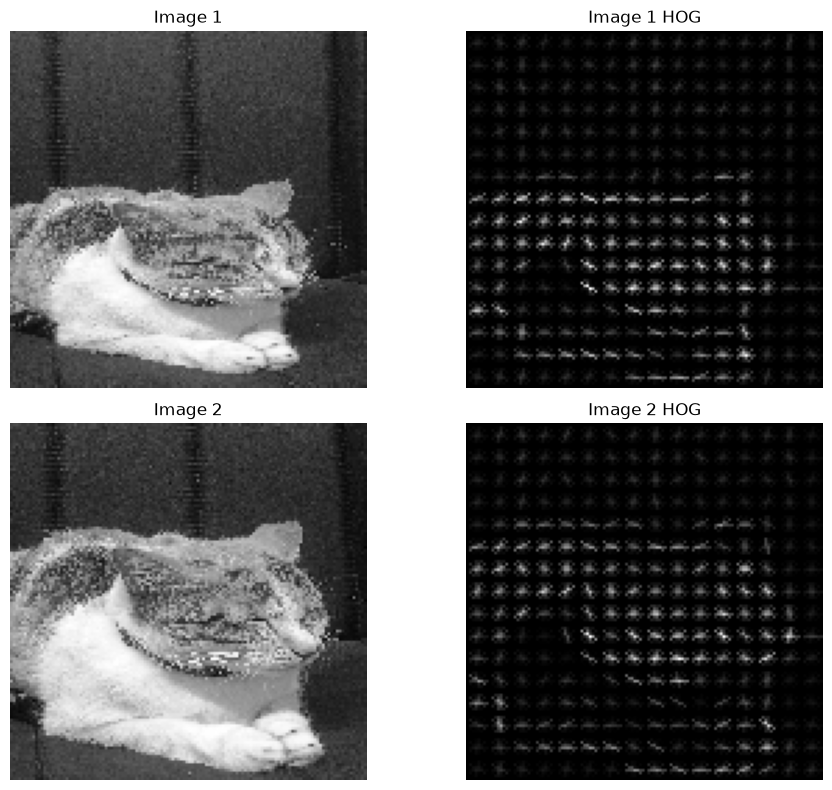

HOG feature vectors saved.


In [2]:

from skimage.feature import hog

# HOG expects a grayscale image
# Resize both images to a common size for comparison
hog_size = (128, 128)

hog_image1 = cv2.resize(gray1, hog_size)
hog_image2 = cv2.resize(gray2, hog_size)

features1, hog_visual1 = hog(
    hog_image1,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

features2, hog_visual2 = hog(
    hog_image2,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

print("HOG feature vector 1:", features1.shape)
print("HOG feature vector 2:", features2.shape)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(hog_image1, cmap="gray")
axes[0, 0].set_title("Image 1")

axes[0, 1].imshow(hog_visual1, cmap="gray")
axes[0, 1].set_title("Image 1 HOG")

axes[1, 0].imshow(hog_image2, cmap="gray")
axes[1, 0].set_title("Image 2")

axes[1, 1].imshow(hog_visual2, cmap="gray")
axes[1, 1].set_title("Image 2 HOG")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

np.save(OUTPUT_DIR / "hog_features_1.npy", features1)
np.save(OUTPUT_DIR / "hog_features_2.npy", features2)

print("HOG feature vectors saved.")


**Observation Image 1 :** The HOG method extracts important shape and edge information from the first image. It divides the image into small regions and calculates the direction of edges, creating numerical features that represent the image's structure.

**Observation Image 2:** HOG extracts shape and edge information from the second image using the same process. These features can be used to describe and compare the visual structure of both images.

## 3. SIFT Keypoints and Descriptors

SIFT detects distinctive keypoints and computes descriptors that represent their local appearance. The images are resized before feature extraction to reduce memory usage.

Image 1 size: (1000, 562)
Image 2 size: (999, 624)
Keypoints in image 1: 1500
Keypoints in image 2: 1500


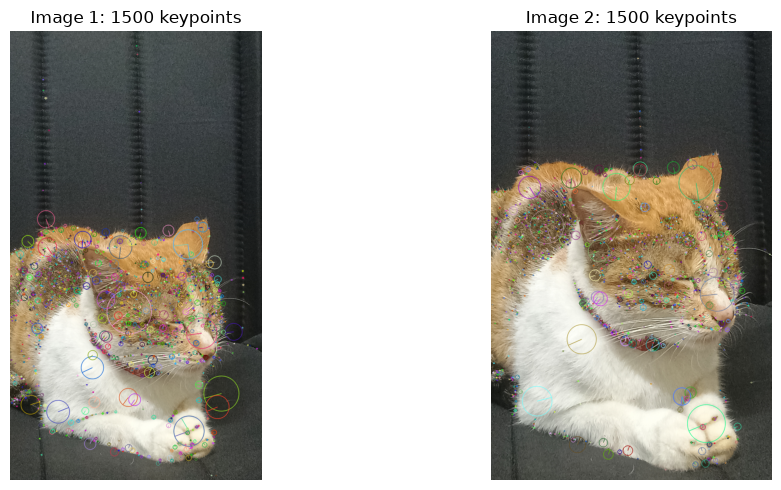

SIFT results saved.


In [4]:

# SIFT with memory-safe image resizing
import cv2
import numpy as np
import matplotlib.pyplot as plt

MAX_DIMENSION = 1000

def resize_for_sift(image, max_dimension=MAX_DIMENSION):
    height, width = image.shape[:2]
    scale = min(1.0, max_dimension / max(height, width))

    if scale < 1.0:
        image = cv2.resize(
            image,
            (int(width * scale), int(height * scale)),
            interpolation=cv2.INTER_AREA
        )

    return image

# Resize the original images before processing
image1_small = resize_for_sift(image1)
image2_small = resize_for_sift(image2)

gray1_small = cv2.cvtColor(image1_small, cv2.COLOR_BGR2GRAY)
gray2_small = cv2.cvtColor(image2_small, cv2.COLOR_BGR2GRAY)

print("Image 1 size:", gray1_small.shape)
print("Image 2 size:", gray2_small.shape)

# Limit the number of SIFT features to reduce memory usage
sift = cv2.SIFT_create(nfeatures=1500)

keypoints1, descriptors1 = sift.detectAndCompute(
    gray1_small, None
)
keypoints2, descriptors2 = sift.detectAndCompute(
    gray2_small, None
)

print("Keypoints in image 1:", len(keypoints1))
print("Keypoints in image 2:", len(keypoints2))

# Draw detected keypoints
keypoint_image1 = cv2.drawKeypoints(
    image1_small,
    keypoints1,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

keypoint_image2 = cv2.drawKeypoints(
    image2_small,
    keypoints2,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cv2.cvtColor(keypoint_image1, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Image 1: {len(keypoints1)} keypoints")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(keypoint_image2, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Image 2: {len(keypoints2)} keypoints")
axes[1].axis("off")

plt.tight_layout()
plt.show()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(OUTPUT_DIR / "sift_keypoints_1.png"),
    keypoint_image1
)
cv2.imwrite(
    str(OUTPUT_DIR / "sift_keypoints_2.png"),
    keypoint_image2
)

if descriptors1 is not None:
    np.save(OUTPUT_DIR / "sift_descriptors_1.npy", descriptors1)

if descriptors2 is not None:
    np.save(OUTPUT_DIR / "sift_descriptors_2.npy", descriptors2)

print("SIFT results saved.")


**Observation Image 1:** SIFT detects important points in the first image, such as corners, edges, and distinctive patterns. These keypoints represent areas that can be recognised even when the image is rotated or resized.

**Observation Image 2:** SIFT identifies distinctive keypoints in the second image. These points provide visual information that can be compared with the keypoints detected in the first image.

## 4. Feature Matching

A brute-force matcher compares SIFT descriptors between the two images. Lowe's ratio test filters ambiguous matches, helping identify more reliable correspondences.

Good SIFT matches: 510


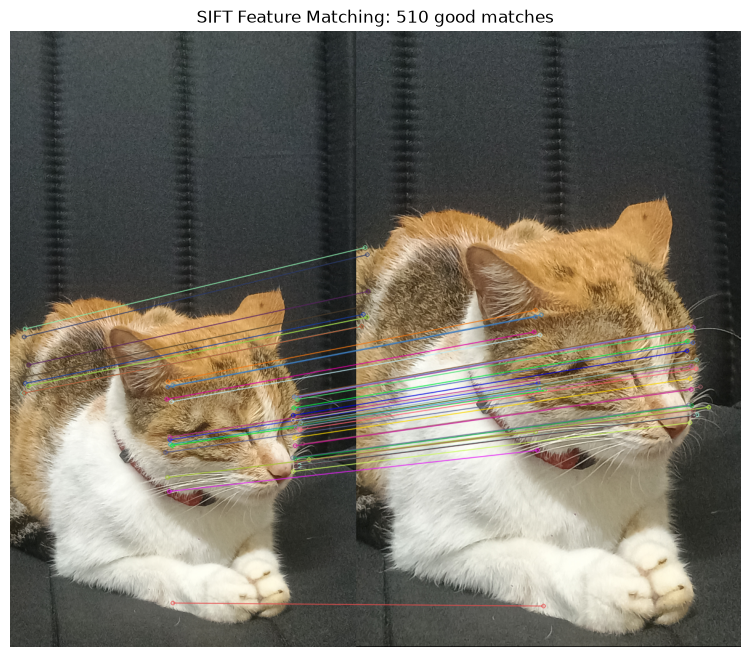

Saved to outputs/sift_matches.png


In [5]:
# Match SIFT descriptors between the two images

if descriptors1 is None or descriptors2 is None:
    print("Not enough features detected. Try using clearer images.")
else:
    # Match descriptors using the Brute-Force matcher
    matcher = cv2.BFMatcher(cv2.NORM_L2)
    pairs = matcher.knnMatch(descriptors1, descriptors2, k=2)

    # Keep good matches using Lowe's ratio test
    good_matches = []
    for pair in pairs:
        if len(pair) == 2:
            m, n = pair
            if m.distance < 0.75 * n.distance:
                good_matches.append(m)

    print("Good SIFT matches:", len(good_matches))

    # Draw the best matches
    matches_image = cv2.drawMatches(
        image1_small, keypoints1,
        image2_small, keypoints2,
        good_matches[:50],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Display the result
    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(matches_image, cv2.COLOR_BGR2RGB))
    plt.title(f"SIFT Feature Matching: {len(good_matches)} good matches")
    plt.axis("off")
    plt.show()

    # Save the result
    cv2.imwrite(str(OUTPUT_DIR / "sift_matches.png"), matches_image)
    print("Saved to outputs/sift_matches.png")

**Observation:** The SIFT descriptors from both images are compared using a Brute-Force Matcher. The Lowe's ratio test removes less reliable matches and keeps stronger feature matches. Our experiment produced **510 good matches**, showing that the images share several similar visual features.

## 5. Matching Under Image Transformations

The first image is rotated and resized to examine how geometric transformations affect SIFT feature matching. The resulting matches are visualized and compared with the original matching experiment.

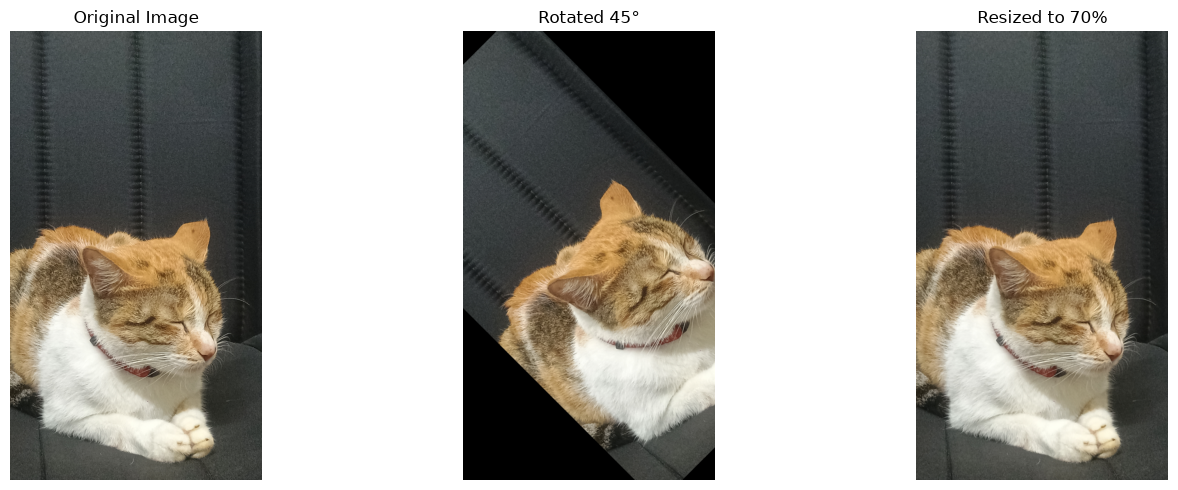

Original keypoints: 1500
Rotated image keypoints: 1500
Resized image keypoints: 775
Rotation and resizing results saved.


In [6]:
# Test SIFT with a rotated and resized image

# Rotate image 1 by 45 degrees
height, width = image1_small.shape[:2]
center = (width // 2, height // 2)

rotation_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated_image = cv2.warpAffine(
    image1_small,
    rotation_matrix,
    (width, height)
)

# Resize image 1 to 70% of its original dimensions
resized_image = cv2.resize(
    image1_small,
    None,
    fx=0.7,
    fy=0.7,
    interpolation=cv2.INTER_AREA
)

# Convert transformed images to grayscale
rotated_gray = cv2.cvtColor(rotated_image, cv2.COLOR_BGR2GRAY)
resized_gray = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)

# Detect SIFT features
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_gray, None
)
resized_keypoints, resized_descriptors = sift.detectAndCompute(
    resized_gray, None
)

# Display the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cv2.cvtColor(image1_small, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Rotated 45°")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
axes[2].set_title("Resized to 70%")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Original keypoints:", len(keypoints1))
print("Rotated image keypoints:", len(rotated_keypoints))
print("Resized image keypoints:", len(resized_keypoints))

# Save the transformed images
cv2.imwrite(str(OUTPUT_DIR / "rotated_image.png"), rotated_image)
cv2.imwrite(str(OUTPUT_DIR / "resized_image.png"), resized_image)

print("Rotation and resizing results saved.")

**Observation:** The first image is rotated by 45 degrees. Its orientation changes, but the main visual features remain present. This experiment tests whether SIFT can recognise matching features despite image rotation.

Good matches with rotated image: 822
Good matches with resized image: 511


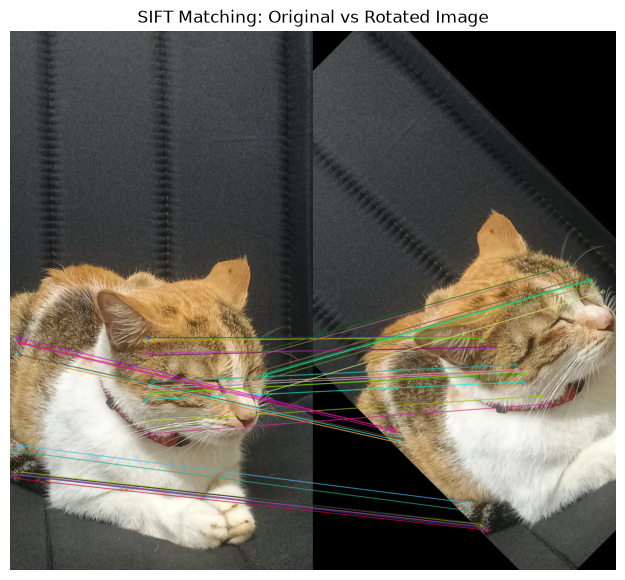

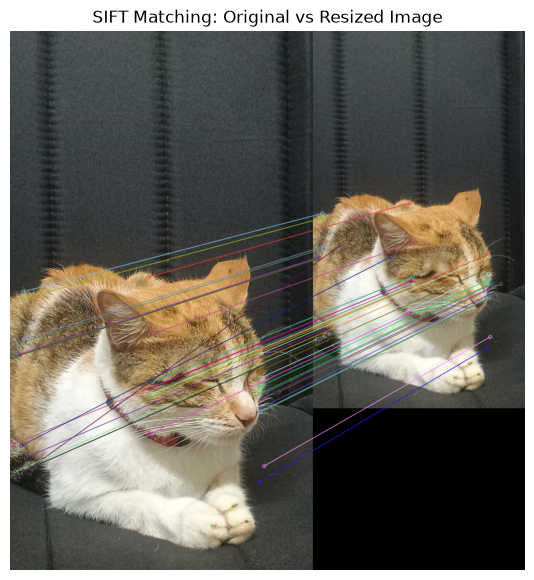

Saved both matching comparison images in the outputs folder.


In [7]:
# Create a matcher for SIFT descriptors
matcher = cv2.BFMatcher(cv2.NORM_L2)

def match_transformed_image(original_descriptors, transformed_descriptors):
    if original_descriptors is None or transformed_descriptors is None:
        return []

    pairs = matcher.knnMatch(
        original_descriptors,
        transformed_descriptors,
        k=2
    )

    good = []
    for pair in pairs:
        if len(pair) == 2:
            m, n = pair
            if m.distance < 0.75 * n.distance:
                good.append(m)

    return good


# Match original image against rotated image
rotated_matches = match_transformed_image(
    descriptors1,
    rotated_descriptors
)

# Match original image against resized image
resized_matches = match_transformed_image(
    descriptors1,
    resized_descriptors
)

print("Good matches with rotated image:", len(rotated_matches))
print("Good matches with resized image:", len(resized_matches))


# Draw and display matches for the rotated image
rotated_match_image = cv2.drawMatches(
    image1_small,
    keypoints1,
    rotated_image,
    rotated_keypoints,
    rotated_matches[:40],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 7))
plt.imshow(cv2.cvtColor(rotated_match_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matching: Original vs Rotated Image")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "sift_rotated_matches.png"),
    rotated_match_image
)


# Draw and display matches for the resized image
resized_match_image = cv2.drawMatches(
    image1_small,
    keypoints1,
    resized_image,
    resized_keypoints,
    resized_matches[:40],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 7))
plt.imshow(cv2.cvtColor(resized_match_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matching: Original vs Resized Image")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "sift_resized_matches.png"),
    resized_match_image
)

print("Saved both matching comparison images in the outputs folder.")

**Observation:** SIFT detects and matches features between the original image and its rotated version. The connecting lines show corresponding keypoints. This demonstrates SIFT's ability to handle changes in image orientation.

**Observation:** SIFT matches keypoints between the original image and the resized image. The matching lines indicate corresponding visual features at different scales. This demonstrates SIFT's ability to recognise features when image size changes.